# CA1 Project for Machine Learning
### Oleksii Taranov
### sba26106@student.cct.ie

The dataset used in the project: **CTG.xls**

Origin of the dataset:
https://archive.ics.uci.edu/dataset/193/cardiotocography

The dataset consists of measurements of fetal heart rate (FHR) and uterine contraction (UC) features on cardiotocograms classified by expert obstetricians.

Additional Information:
2126 fetal cardiotocograms (CTGs) were automatically processed and the respective diagnostic features measured. The CTGs were also classified by three expert obstetricians and a consensus classification label assigned to each of them. Classification was both with respect to a morphologic pattern (A, B, C. ...) and to a fetal state (N, S, P).

In [1]:
# Install package for read Excel
!pip install xlrd

In [2]:
# import libraries
import pandas as pd
import numpy as np

## 1. Data Loading

In [3]:
# Load and have a look at the dataset
df = pd.read_excel('CTG.xls')

df.head()

,Unnamed: 0,Unnamed: 1,Cardiotocographic data,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,NaN,NaN,2126 measurements and classifications of foeta...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Worksheet,NaN,Raw Data,NaN,NaN,NaN,NaN,NaN,NaN,Data (temporal features per unit time),NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,K-W,NaN,DR is removed since p(K-W)=1
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Features,NaN,chi-square,p,NaN


By default it loaded the first sheet, that has no data. The file CTG.xls contains 3 sheets. The sheet that contains the actual data is 'Raw Data'. Load the data from the target sheet.

In [4]:
df = pd.read_excel('CTG.xls', sheet_name='Raw Data')

In [5]:
df.head()

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Variab10.txt,1996-12-01,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,1996-05-03,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,1996-05-03,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,1996-05-03,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0


The dataset loaded correctly. 
The sheet contains empty rows. 
The target value is 'NSP' (1 = Normal, 2 = Suspect, 3 = Pathologic), because it is clinically meaningful.

In [6]:
df = df.dropna(subset=['NSP'])   # removes the rows with missing values in 'NSP' feature

In [7]:
df.head()

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
1,Variab10.txt,1996-12-01,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,1996-05-03,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,1996-05-03,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,1996-05-03,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
5,Fmcs_1.txt,1996-05-03,CTG0005.txt,533.0,1147.0,132.0,132.0,4.0,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0


## 2. Data Understanding

After removing the empty rows, the dataset is inspected to confirm its size, the data types of the columns and whether any missing values remain.

In [8]:
# Size of the dataset (rows, columns)
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

# Total number of missing values left in the dataset
print('Missing values:', df.isnull().sum().sum())

Rows: 2126
Columns: 40
Missing values: 0


In [9]:
# Data types of all columns
df.dtypes.value_counts()

float64           37
str                2
datetime64[us]     1
Name: count, dtype: int64

The dataset contains 2126 records and 40 columns, which matches the description provided by the UCI Machine Learning Repository. No missing values remain after the empty rows were removed.

## 3. Feature Review

Not every column in the dataset is suitable as an input for a machine learning model. According to the *Description* sheet of the original file (Ayres de Campos et al., 2000), the columns belong to three groups:

| Group | Columns | Meaning |
|---|---|---|
| Exam data | `FileName`, `Date`, `SegFile`, `b`, `e` | Administrative information about the recording |
| Measurements | `LBE`, `LB`, `AC`, `FM`, `UC`, `ASTV`, `MSTV`, `ALTV`, `MLTV`, `DL`, `DS`, `DP`, `DR`, `Width`, `Min`, `Max`, `Nmax`, `Nzeros`, `Mode`, `Mean`, `Median`, `Variance`, `Tendency` | Values measured from the fetal heart rate signal |
| Classification | `A`, `B`, `C`, `D`, `E`, `AD`, `DE`, `LD`, `FS`, `SUSP`, `CLASS`, `NSP` | Labels assigned by expert obstetricians |

Each column is assessed with one main question: *would this value be available before the diagnosis is made?* Columns that are created by the diagnosis itself would cause **data leakage**, which means the model would learn the answer instead of learning from the signal.

### 3.1 Identifier columns

A column with a unique value in almost every row behaves as an identifier and does not carry information about the fetal state.

In [10]:
# Number of unique values in the exam data columns
exam_cols = ['FileName', 'Date', 'SegFile', 'b', 'e']
pd.DataFrame({'Unique values': df[exam_cols].nunique(),
              'Total rows': len(df)})

,Unique values,Total rows
FileName,352,2126
Date,48,2126
SegFile,2126,2126
b,979,2126
e,1064,2126


`SegFile` has a unique value for every row, so it is a pure record identifier. `FileName` and `Date` identify the patient file and the examination date, while `b` and `e` are the start and end positions of the analysed segment in the recording. None of these columns describes the condition of the fetus, therefore they are excluded.

### 3.2 Constant columns

A column with only one value cannot help to distinguish between classes.

In [11]:
# Columns with only one unique value
n_unique = df.nunique()
n_unique[n_unique == 1]

DR    1
dtype: int64

`DR` (repetitive decelerations) is equal to 0 in every record. This agrees with the note in the original file, "DR is removed since p(K-W)=1", so the column is excluded.

### 3.3 Duplicated columns

Two columns with identical values provide the same information twice.

In [12]:
# Check if the baseline value from the expert (LBE) equals the baseline value from the software (LB)
print('LB and LBE are identical:', (df['LB'] == df['LBE']).all())

LB and LBE are identical: True


`LBE` (baseline value given by a medical expert) is identical to `LB` (baseline value calculated by the SisPorto software). `LB` is kept because it is produced automatically, which is consistent with the aim of an automated diagnostic model. `LBE` is excluded.

### 3.4 Data leakage check

The relationship between the morphologic class (`CLASS`) and the target (`NSP`) is examined with a contingency table.

In [13]:
# Contingency table between the 10-class label and the 3-class target
pd.crosstab(df['CLASS'], df['NSP'])

NSP,1.0,2.0,3.0
CLASS,,,
1.0,382,2,0
2.0,579,0,0
3.0,53,0,0
4.0,81,0,0
5.0,3,69,0
6.0,330,2,0
7.0,227,25,0
8.0,0,0,107
9.0,0,1,68


The table shows that `CLASS` almost fully determines `NSP`. For example, every record with `CLASS = 8` is Pathologic, and almost every record with `CLASS = 10` is Suspect. Using `CLASS` as an input would therefore give the model the answer directly.

The columns `A` to `SUSP` are the same information as `CLASS`, written as separate 0/1 indicators. This is confirmed below: every record has exactly one indicator equal to 1.

In [14]:
# Sum of the pattern indicators in each row
pattern_cols = ['A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP']
df[pattern_cols].sum(axis=1).value_counts()

1.0    2126
Name: count, dtype: int64

All 2126 records have a sum of 1, which means that the indicator columns are an alternative coding of `CLASS`. All of them are excluded to avoid data leakage.

### 3.5 Summary of the feature decisions

The table below summarises the decision taken for every column of the dataset.

In [15]:
# Reason for every excluded column
excluded = {
    'FileName': 'Identifier (exam data)',
    'Date':     'Identifier (exam data)',
    'SegFile':  'Identifier (unique for every row)',
    'b':        'Start position of the segment (exam data)',
    'e':        'End position of the segment (exam data)',
    'LBE':      'Duplicate of LB',
    'DR':       'Constant value (always 0)',
    'CLASS':    'Data leakage (expert label)',
    'NSP':      'Target variable',
}
for col in pattern_cols:
    excluded[col] = 'Data leakage (expert label, coding of CLASS)'

# Build the decision table for all columns
decision_table = pd.DataFrame({
    'Column': df.columns,
    'Unique values': df.nunique().values,
    'Decision': ['Target' if c == 'NSP' else ('Exclude' if c in excluded else 'Keep') for c in df.columns],
    'Reason': [excluded.get(c, 'Measured from the CTG signal') for c in df.columns],
})
decision_table

,Column,Unique values,Decision,Reason
0,FileName,352,Exclude,Identifier (exam data)
1,Date,48,Exclude,Identifier (exam data)
2,SegFile,2126,Exclude,Identifier (unique for every row)
3,b,979,Exclude,Start position of the segment (exam data)
4,e,1064,Exclude,End position of the segment (exam data)
5,LBE,48,Exclude,Duplicate of LB
6,LB,48,Keep,Measured from the CTG signal
7,AC,22,Keep,Measured from the CTG signal
8,FM,96,Keep,Measured from the CTG signal
9,UC,19,Keep,Measured from the CTG signal


In [16]:
# Number of columns in each decision group
decision_table['Decision'].value_counts()

Decision
Keep       21
Exclude    18
Target      1
Name: count, dtype: int64

In total, 21 measurement columns are kept as input features, 18 columns are excluded and `NSP` is used as the target variable.

## 4. Data Preparation

### 4.1 Removing the excluded columns

In [17]:
# Keep only the selected features and the target
drop_cols = [c for c in excluded if c != 'NSP']
df_clean = df.drop(columns=drop_cols)

print('Shape after removing columns:', df_clean.shape)

Shape after removing columns: (2126, 22)


### 4.2 Duplicated records

Duplicated rows can appear in both the training and the test set, which may make the test results look better than they really are.

In [18]:
# Number of fully duplicated rows (same features and same target)
print('Duplicated rows:', df_clean.duplicated().sum())

# Remove the duplicated rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df_clean.shape)

Duplicated rows: 14
Shape after removing duplicates: (2112, 22)


### 4.3 Target variable

The target `NSP` is stored as a decimal number, so it is converted to an integer class label. The class distribution is then examined.

In [19]:
# Convert the target to integer
df_clean['NSP'] = df_clean['NSP'].astype(int)

# Class distribution of the target
class_names = {1: 'Normal', 2: 'Suspect', 3: 'Pathologic'}
class_table = pd.DataFrame({
    'Class': [class_names[c] for c in sorted(df_clean['NSP'].unique())],
    'Count': df_clean['NSP'].value_counts().sort_index().values,
})
class_table['Percentage (%)'] = (class_table['Count'] / class_table['Count'].sum() * 100).round(1)
class_table

,Class,Count,Percentage (%)
0,Normal,1646,77.9
1,Suspect,292,13.8
2,Pathologic,174,8.2


The target is imbalanced: about three quarters of the records are Normal, while the Suspect and Pathologic classes are much smaller. Because of this, accuracy alone can be misleading, since a model that always predicts Normal would already reach about 78% accuracy. Stratified data splits and additional metrics such as the macro F1-score will therefore be used in the modelling stage.

### 4.4 Features and target

In [20]:
# Separate the input features (X) and the target (y)
X = df_clean.drop(columns='NSP')
y = df_clean['NSP']

print('Features (X):', X.shape)
print('Target (y):', y.shape)
print('Feature names:', list(X.columns))

Features (X): (2112, 21)
Target (y): (2112,)
Feature names: ['LB', 'AC', 'FM', 'UC', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency']


The final dataset contains 2112 records and 21 numerical input features, which satisfies the requirement of at least 5 columns and more than 300 rows after pre-processing.

## 5. Exploratory Analysis and Feature Significance

This section explores the prepared data visually and then uses a statistical test to show which features differ significantly between the three fetal states.

In [21]:
# Libraries for visualisation, statistics and modelling
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway, spearmanr

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

### 5.1 Visualisations

**Class distribution**

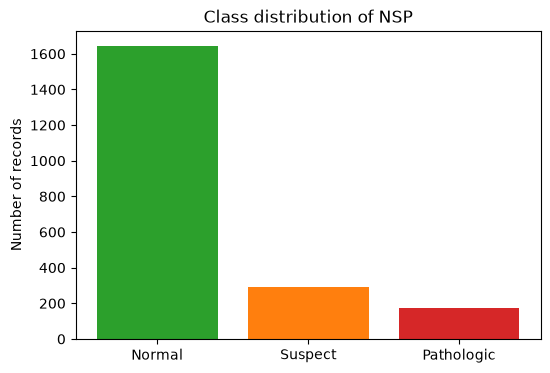

In [22]:
# Bar chart of the class distribution (from the table in section 4.3)
plt.figure(figsize=(6, 4))
plt.bar(class_table['Class'], class_table['Count'], color=['tab:green', 'tab:orange', 'tab:red'])
plt.title('Class distribution of NSP')
plt.ylabel('Number of records')
plt.show()

The chart confirms the imbalance found in section 4.3: the Normal class is much larger than the Suspect and Pathologic classes.

**Correlation between features**

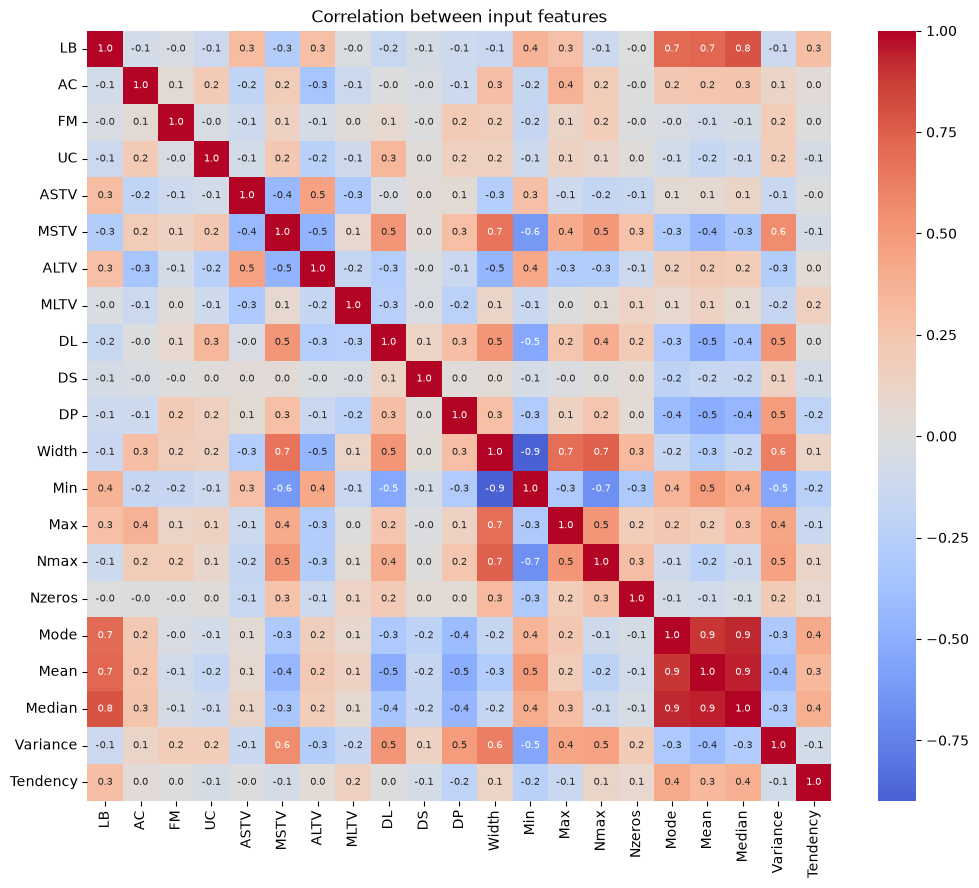

In [23]:
# Correlation heatmap of the input features
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation between input features')
plt.show()

In [24]:
# Correlation between the three histogram centre measures
X[['Mode', 'Mean', 'Median']].corr().round(2)

,Mode,Mean,Median
Mode,1.00,0.89,0.93
Mean,0.89,1.00,0.95
Median,0.93,0.95,1.00


`Mode`, `Mean` and `Median` are strongly correlated, because all three describe the centre of the same FHR histogram. This matters when feature importance is interpreted in section 9: a model can split the importance between correlated features, so each of them may look less important than the information they share really is. Random Forest handles correlated features without problems in terms of accuracy, so they are kept.

**Distribution of selected features by class**

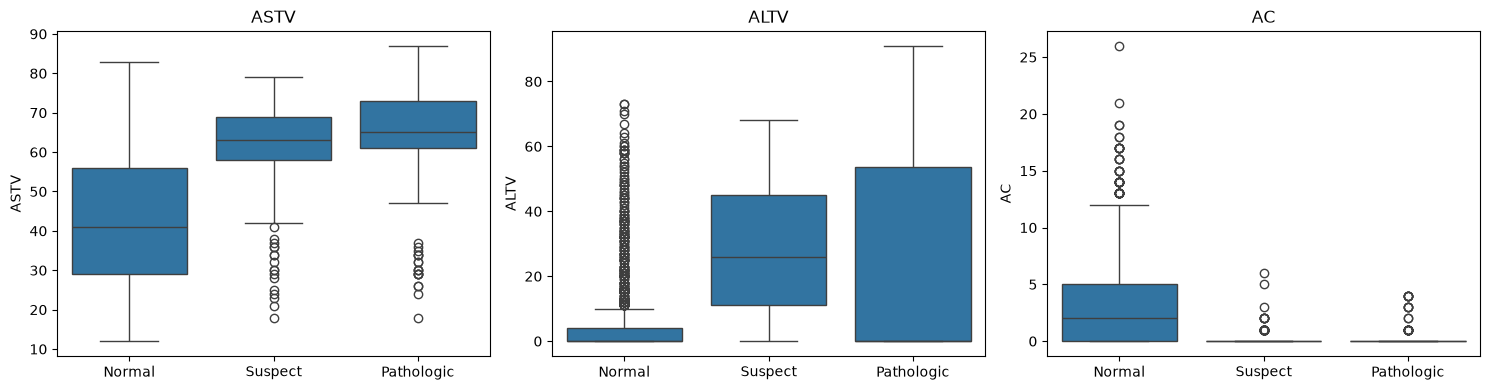

In [25]:
# Boxplots of three features for each class of NSP
features_to_plot = ['ASTV', 'ALTV', 'AC']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features_to_plot):
    sns.boxplot(x=y.map(class_names), y=X[col], order=['Normal', 'Suspect', 'Pathologic'], ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

The boxplots show clear differences between the classes. Abnormal short-term variability (`ASTV`) and abnormal long-term variability (`ALTV`) are higher in the Suspect and Pathologic groups, while accelerations (`AC`) are mostly close to zero outside the Normal group. The distributions are also skewed and contain many outliers. This is checked with the skewness and kurtosis of each feature below.

In [26]:
# Skewness and kurtosis of each feature (0 = same shape as a normal distribution)
shape_table = pd.DataFrame({'Skewness': X.skew(), 'Kurtosis': X.kurt()}).round(2)
shape_table.sort_values('Skewness', key=abs, ascending=False)

,Skewness,Kurtosis
DS,17.30,297.42
FM,9.40,103.94
DP,4.22,19.07
Nzeros,3.91,30.19
Variance,3.21,15.04
ALTV,2.21,4.32
DL,1.81,3.11
MSTV,1.66,4.69
AC,1.65,3.09
MLTV,1.34,4.17


Many features have a skewness far from 0 (values above 1 or below -1 indicate strong skew) and a high kurtosis, which means heavy tails and outliers. So many features are not normally distributed.

### 5.2 Statistical test: one-way ANOVA (F test)

A one-way ANOVA checks whether the mean of a feature is the same in all three classes. It is used here because:

- the target has **three groups**. A Student's t-test can only compare two groups, and running three separate t-tests would increase the risk of a Type I error (a false positive);
- the features are numerical and the target is categorical, which is the setting ANOVA is designed for. The chi-square test is meant for two categorical variables, so it does not fit here.

Hypotheses for each feature (significance level alpha = 0.05):
- H0: the mean of the feature is the same in Normal, Suspect and Pathologic records;
- H1: at least one class has a different mean.

The **F statistic** compares the variation between the class means with the variation inside the classes. A larger F means the classes are more clearly separated by that feature. If p < 0.05, H0 is rejected.

**Assumptions.** ANOVA assumes approximately normal data in each group. Section 5.1 showed that many features are skewed. However, the groups are large (174 to 1646 records), so by the **Central Limit Theorem** the sampling distribution of each group mean is close to normal, and ANOVA is still reasonably reliable. The p-values should be treated as approximate, but for features with very small p-values the conclusion does not change.

In [27]:
# One-way ANOVA for every feature across the three classes
anova_results = []
for col in X.columns:
    groups = [X.loc[y == c, col] for c in [1, 2, 3]]   # values of the feature in each class
    f_stat, p_value = f_oneway(*groups)
    anova_results.append({'Feature': col, 'F statistic': f_stat, 'p-value': p_value})

anova_table = pd.DataFrame(anova_results).sort_values('F statistic', ascending=False).reset_index(drop=True)
anova_table['Significant (p < 0.05)'] = anova_table['p-value'] < 0.05
anova_table

,Feature,F statistic,p-value,Significant (p < 0.05)
0,DP,546.461581,6.066711e-192,True
1,ASTV,335.871825,2.349780e-127,True
2,ALTV,334.227343,8.184850e-127,True
3,Mean,302.528939,3.071902e-116,True
4,Mode,279.650376,1.880093e-108,True
5,Median,252.751717,3.997832e-99,True
6,AC,166.384894,8.019190e-68,True
7,Variance,152.670451,1.195744e-62,True
8,LB,138.372184,3.422498e-57,True
9,MSTV,118.595857,1.550408e-49,True


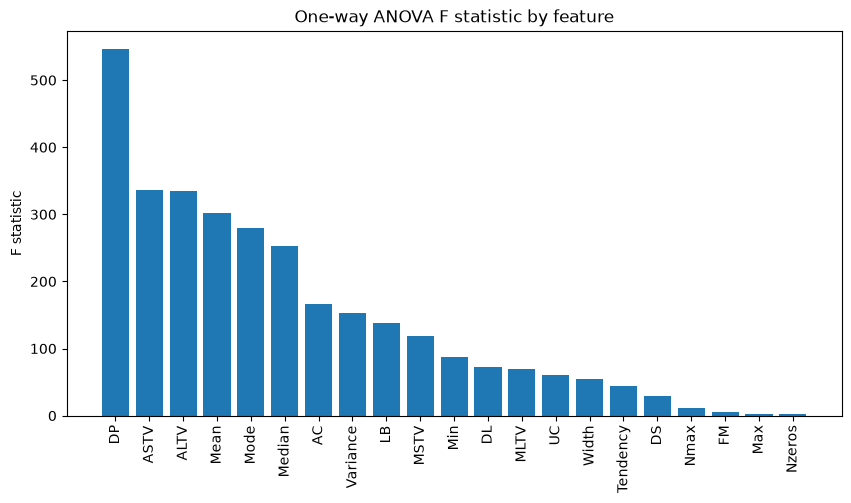

In [28]:
# Bar chart of the F statistic for each feature
plt.figure(figsize=(10, 5))
plt.bar(anova_table['Feature'], anova_table['F statistic'])
plt.xticks(rotation=90)
plt.title('One-way ANOVA F statistic by feature')
plt.ylabel('F statistic')
plt.show()

19 of the 21 features have p-values below 0.05, so H0 is rejected for them: their mean values differ significantly between Normal, Suspect and Pathologic records. Only `Max` (p = 0.086) and `Nzeros` (p = 0.117) are not significant. The features with the highest F statistic (shown at the top of the table) separate the classes most strongly.

## 6. Model Selection and Justification

Two classification models are used. Both are suitable for a multi-class problem with 21 numerical features and about 2100 records.

| Model | Why it suits this data |
|---|---|
| **Random Forest** (Breiman, 2001) | An ensemble of decision trees. It handles non-linear relationships and correlated features (such as `Mode`, `Mean`, `Median`), does not need feature scaling, can deal with class imbalance through `class_weight='balanced'`, and provides feature importances that help to interpret the model. |
| **Support Vector Machine, RBF kernel** (Cortes and Vapnik, 1995) | Performs well on small and medium-sized numerical datasets and can find complex, non-linear class boundaries through the RBF kernel. It is sensitive to the scale of the features, which matters here because the values range from about 0.001 (`AC`) to over 200 (`Width`). |

Both models use `class_weight='balanced'`, which gives more weight to the smaller Suspect and Pathologic classes during training.

**Avoiding data leakage when scaling.** The SVM is placed in a `Pipeline` together with `StandardScaler`. The pipeline fits the scaler only on the training data, and in cross-validation it fits it again inside every fold. If the whole `X` was scaled before splitting, the mean and standard deviation of the test records would be used to transform the training data, so information from the test set would leak into training and the results would be too optimistic.

In [29]:
# The two models with default hyperparameters
models = {
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'SVM': Pipeline([
        ('scaler', StandardScaler()), # scaling is fitted on training data only
        ('svc', SVC(kernel='rbf', class_weight='balanced', random_state=42)),
    ]),
}

## 7. Model Accuracy Across Three Data Splits

The data is split three times, with **5%, 15% and 25%** of the records held out as the test set. In this notebook the three splits are treated as test-set sizes, so the training sets contain 95%, 85% and 75% of the records. For every split and every model:

1. `train_test_split` with `stratify=y`, so each split keeps the original class proportions;
2. 5-fold **stratified cross-validation** on the training set only, to estimate how well the model generalises and how much the score varies (standard deviation);
3. the model is fitted on the full training set and evaluated once on the test set.

Accuracy and macro-F1 are both recorded, because accuracy alone can be misleading with imbalanced classes (section 4.3).

In [30]:
# Evaluate both models on the three splits
test_sizes = [0.05, 0.15, 0.25]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
for size in test_sizes:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=size, stratify=y, random_state=42)

    for name, base_model in models.items():
        model = clone(base_model) 

        # Cross-validation on the training set only
        cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy')

        # Fit on the whole training set and evaluate on the test set
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)

        results.append({
            'Test size': f'{int(size * 100)}%',
            'Model': name,
            'Train rows': len(X_tr),
            'Test rows': len(X_te),
            'Pathologic in test': (y_te == 3).sum(),
            'CV mean': cv_scores.mean(),
            'CV std': cv_scores.std(),
            'Train accuracy': accuracy_score(y_tr, model.predict(X_tr)),
            'Test accuracy': accuracy_score(y_te, y_pred),
            'Test macro-F1': f1_score(y_te, y_pred, average='macro'),
        })

results_df = pd.DataFrame(results).round(3)
results_df

,Test size,Model,Train rows,Test rows,Pathologic in test,CV mean,CV std,Train accuracy,Test accuracy,Test macro-F1
0,5%,Random Forest,2006,106,9,0.938,0.008,0.990,0.943,0.897
1,5%,SVM,2006,106,9,0.873,0.006,0.903,0.877,0.814
2,15%,Random Forest,1795,317,26,0.937,0.006,0.991,0.956,0.924
3,15%,SVM,1795,317,26,0.875,0.006,0.900,0.893,0.829
4,25%,Random Forest,1584,528,43,0.935,0.010,0.991,0.953,0.912
5,25%,SVM,1584,528,43,0.871,0.022,0.896,0.886,0.837


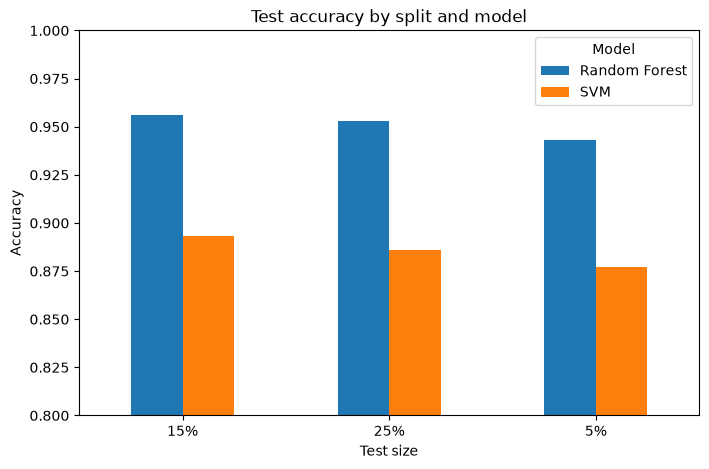

In [31]:
# Grouped bar chart of test accuracy by split and model
ax = results_df.pivot(index='Test size', columns='Model', values='Test accuracy').plot(kind='bar', figsize=(8, 5))
ax.set_title('Test accuracy by split and model')
ax.set_ylabel('Accuracy')
ax.set_ylim(0.8, 1.0)
ax.tick_params(axis='x', rotation=0)
plt.show()

**Discussion**

- **The 5% split is unreliable.** Its test set has only 106 records, and only 9 of them are Pathologic. One wrong prediction changes accuracy by about 1%, so the test score depends heavily on which records happened to be chosen. In this run the 5% test score is close to the CV mean, but with so few test records this could easily be chance. The cross-validation score is more trustworthy because it averages five estimates, and its standard deviation shows how much the score varies.
- **The 15% and 25% splits** have larger test sets (317 and 528 records), so their test scores are less sensitive to individual records. Their test accuracy is about 0.02 higher than the CV mean for both models, which is a small difference.
- **Random Forest vs SVM.** The Random Forest has higher CV accuracy, test accuracy and macro-F1 in every split.
- **Training accuracy.** The Random Forest reaches a training accuracy of about 0.99 against a CV accuracy of about 0.94, so it fits the training data almost perfectly and overfits slightly. The SVM has a training accuracy of about 0.90 against a CV accuracy of about 0.87, a much smaller gap, but its overall accuracy is lower.

## 8. Hyperparameter Tuning

**Purpose.** Hyperparameters are settings chosen before training, such as the depth of the trees in a Random Forest or the parameter `C` of an SVM. They control the complexity of the model, and therefore the balance between underfitting (model too simple) and overfitting (model memorises the training data). Tuning searches for the values that generalise best, judged by cross-validation on the training data and not by the test set, so the test set stays an independent final check.

**Technique.** `GridSearchCV` tries every combination of the values in a grid and evaluates each one with 5-fold stratified cross-validation. The combination with the best mean score is selected and refitted on the whole training set (Pedregosa et al., 2011).

**Split and metric.** The 25% split is used, because it has the largest and most reliable test set (about 528 records). The scoring metric is **macro-F1**, which gives the same weight to every class and therefore does not ignore the small Suspect and Pathologic classes (section 4.3).

In [32]:
# Use the 25% split for tuning
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Training rows: 1584 | Test rows: 528


### 8.1 Random Forest

- `n_estimators`: number of trees;
- `max_depth`: maximum depth of each tree (`None` = trees grow until the leaves are pure);
- `min_samples_leaf`: minimum number of records in a leaf. Larger values make the trees simpler and reduce overfitting.

In [33]:
# Grid search for Random Forest
rf_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
}
rf_search = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                         rf_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
rf_search.fit(X_train, y_train)

print('Best parameters:', rf_search.best_params_)
print('Best CV macro-F1:', round(rf_search.best_score_, 3))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV macro-F1: 0.895


### 8.2 SVM

- `C`: how strongly misclassified training records are penalised. Large `C` gives a more complex boundary (risk of overfitting), small `C` a smoother one (risk of underfitting);
- `gamma`: how far the influence of a single record reaches in the RBF kernel. Large values give very local, complex boundaries.

Because the SVM is inside a pipeline, the parameter names have the prefix `svc__`. The grid for `C` includes 1000, so that if the best value is 100 it is not simply the largest value that was tried.

In [34]:
# Grid search for SVM (scaler + SVC pipeline)
svm_grid = {
    'svc__C': [0.1, 1, 10, 100, 1000],
    'svc__gamma': ['scale', 0.01, 0.1],
}
svm_search = GridSearchCV(clone(models['SVM']), svm_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
svm_search.fit(X_train, y_train)

print('Best parameters:', svm_search.best_params_)
print('Best CV macro-F1:', round(svm_search.best_score_, 3))

Best parameters: {'svc__C': 100, 'svc__gamma': 'scale'}
Best CV macro-F1: 0.845


### 8.3 Default vs tuned models

In [35]:
# Compare default and tuned models on the same 25% test set
tuned_models = {'Random Forest': rf_search.best_estimator_, 'SVM': svm_search.best_estimator_}

comparison = []
for name in models:
    default_model = clone(models[name]).fit(X_train, y_train)
    for version, model in [('Default', default_model), ('Tuned', tuned_models[name])]:
        train_acc = accuracy_score(y_train, model.predict(X_train))
        y_pred = model.predict(X_test)
        test_acc = accuracy_score(y_test, y_pred)
        comparison.append({
            'Model': name,
            'Version': version,
            'Train accuracy': train_acc,
            'Test accuracy': test_acc,
            'Test macro-F1': f1_score(y_test, y_pred, average='macro'),
            'Train-test gap': train_acc - test_acc,
        })

comparison_df = pd.DataFrame(comparison).round(3)
comparison_df

,Model,Version,Train accuracy,Test accuracy,Test macro-F1,Train-test gap
0,Random Forest,Default,0.991,0.953,0.912,0.038
1,Random Forest,Tuned,0.992,0.956,0.921,0.036
2,SVM,Default,0.896,0.886,0.837,0.010
3,SVM,Tuned,0.980,0.926,0.864,0.054


Tuning helped the SVM most: its test macro-F1 rose from 0.837 to 0.864 and its test accuracy from 0.886 to 0.926. However, the chosen `C = 100` makes the decision boundary more complex, so the train-test gap of the SVM grew from 0.010 to 0.054, which is a sign of more overfitting.

For the Random Forest, tuning gave only a small gain (macro-F1 from 0.912 to 0.921). The best parameters (`max_depth = None`, `min_samples_leaf = 1`) still allow fully grown trees, so the training accuracy stays at about 0.99. The tuned Random Forest has the best test accuracy and macro-F1 of all four models.

## 9. Evaluation and Interpretation

### 9.1 Confusion matrices

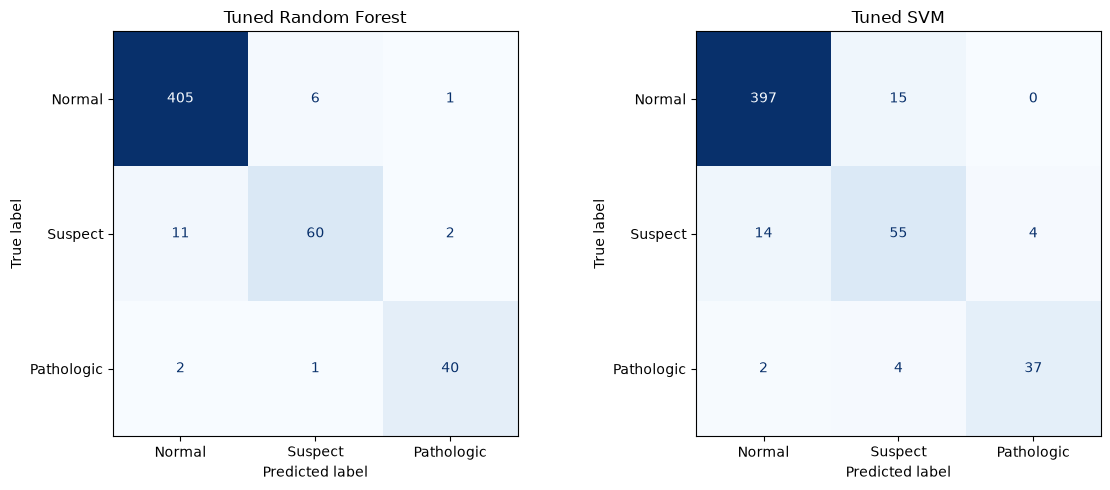

In [36]:
# Confusion matrices of the tuned models on the test set
labels = ['Normal', 'Suspect', 'Pathologic']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=labels,
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'Tuned {name}')
plt.tight_layout()
plt.show()

### 9.2 Classification report

The most important metric for this problem is the **recall of the Pathologic class**: the share of truly pathologic cases that the model detects. In a clinical setting, missing a pathologic fetus (false negative) can lead to a delayed intervention, which is far more costly than a false alarm that is checked again by a clinician.

In [37]:
# Precision, recall and F1-score for each class
for name, model in tuned_models.items():
    print(f'===== Tuned {name} =====')
    print(classification_report(y_test, model.predict(X_test), target_names=labels, digits=3))

===== Tuned Random Forest =====
              precision    recall  f1-score   support

      Normal      0.969     0.983     0.976       412
     Suspect      0.896     0.822     0.857        73
  Pathologic      0.930     0.930     0.930        43

    accuracy                          0.956       528
   macro avg      0.932     0.912     0.921       528
weighted avg      0.956     0.956     0.956       528

===== Tuned SVM =====
              precision    recall  f1-score   support

      Normal      0.961     0.964     0.962       412
     Suspect      0.743     0.753     0.748        73
  Pathologic      0.902     0.860     0.881        43

    accuracy                          0.926       528
   macro avg      0.869     0.859     0.864       528
weighted avg      0.926     0.926     0.926       528



The recall of the Pathologic class is 0.93 for the tuned Random Forest and 0.86 for the tuned SVM. The Random Forest therefore misses fewer pathologic cases (3 of 43 against 6 of 43).

### 9.3 Feature importance vs statistical significance

The importance of each feature is measured in two ways and compared with the ANOVA ranking from section 5.2:

- **Random Forest importance** (`feature_importances_`): how much each feature reduces impurity across all trees;
- **Permutation importance for SVM**: how much the macro-F1 on the test set drops when the values of one feature are randomly shuffled. The SVM has no built-in importance, so this model-independent method is used.

In [38]:
# Random Forest built-in importance
rf_importance = pd.Series(tuned_models['Random Forest'].feature_importances_, index=X.columns)

# SVM permutation importance on the test set
perm = permutation_importance(tuned_models['SVM'], X_test, y_test, scoring='f1_macro',
                              n_repeats=10, random_state=42, n_jobs=-1)
svm_importance = pd.Series(perm.importances_mean, index=X.columns)

# Combine with the ANOVA results
importance_table = pd.DataFrame({
    'ANOVA F statistic': anova_table.set_index('Feature')['F statistic'],
    'RF importance': rf_importance,
    'SVM permutation importance': svm_importance,
})
importance_table['ANOVA rank'] = importance_table['ANOVA F statistic'].rank(ascending=False).astype(int)
importance_table['RF rank'] = importance_table['RF importance'].rank(ascending=False).astype(int)
importance_table['SVM rank'] = importance_table['SVM permutation importance'].rank(ascending=False).astype(int)
importance_table = importance_table.sort_values('ANOVA rank').round(4)
importance_table

,ANOVA F statistic,RF importance,SVM permutation importance,ANOVA rank,RF rank,SVM rank
DP,546.4616,0.0370,0.0311,1,11,11
ASTV,335.8718,0.1457,0.1199,2,1,1
ALTV,334.2273,0.1267,0.0706,3,2,6
Mean,302.5289,0.1057,0.0350,4,3,8
Mode,279.6504,0.0511,0.1028,5,8,2
Median,252.7517,0.0797,0.0899,6,4,4
AC,166.3849,0.0732,0.0997,7,5,3
Variance,152.6705,0.0385,0.0232,8,10,15
LB,138.3722,0.0435,0.0157,9,9,17
MSTV,118.5959,0.0642,0.0799,10,7,5


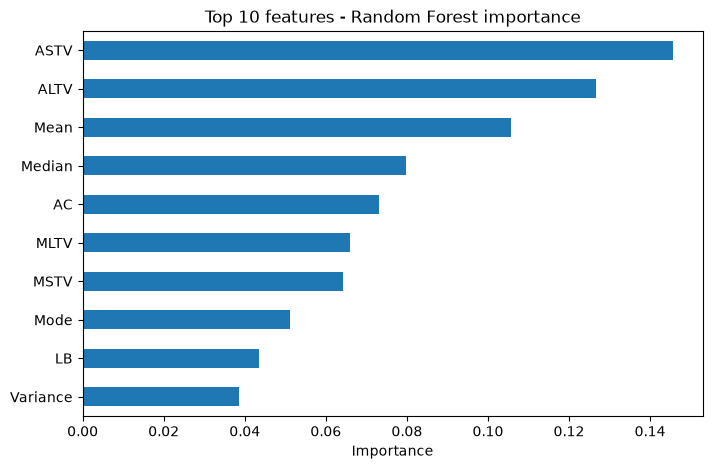

In [39]:
# Top 10 features of the Random Forest
rf_importance.sort_values().tail(10).plot(kind='barh', figsize=(8, 5))
plt.title('Top 10 features - Random Forest importance')
plt.xlabel('Importance')
plt.show()

In [40]:
# Spearman rank correlation between the rankings: do the statistical test and the models agree?
for col, imp in [('RF', 'RF importance'), ('SVM', 'SVM permutation importance')]:
    rho, p = spearmanr(importance_table['ANOVA F statistic'], importance_table[imp])
    print(f'ANOVA vs {col} importance: Spearman rho = {rho:.2f}, p-value = {p:.4f}')

ANOVA vs RF importance: Spearman rho = 0.80, p-value = 0.0000
ANOVA vs SVM importance: Spearman rho = 0.67, p-value = 0.0009


A positive and significant correlation between the rankings (p < 0.05) means that the features which differ most between the classes in the statistical test are also the features the models rely on most. This agreement is the statistical justification of the impact of these features on model performance. Clinically, this is expected: abnormal variability of the fetal heart rate is a well-known sign of fetal distress.

The Spearman rank correlation is used because it compares the order of the features, not the size of the values, which are on different scales for the ANOVA and the two models.

Differences between the rankings can be explained by correlated features. The clearest case is `DP` (prolonged decelerations): it has the highest F statistic in the ANOVA, but it ranks only 11th in both models. Most records have `DP = 0`, and its information probably overlaps with other features such as `ASTV` and the histogram measures, so the models can make the same splits without it. Similarly, `Mode`, `Mean` and `Median` carry similar information, so a model may use one of them and give low importance to the others, even though all three are significant in the ANOVA.

### 9.4 Overfitting, underfitting and generalisation

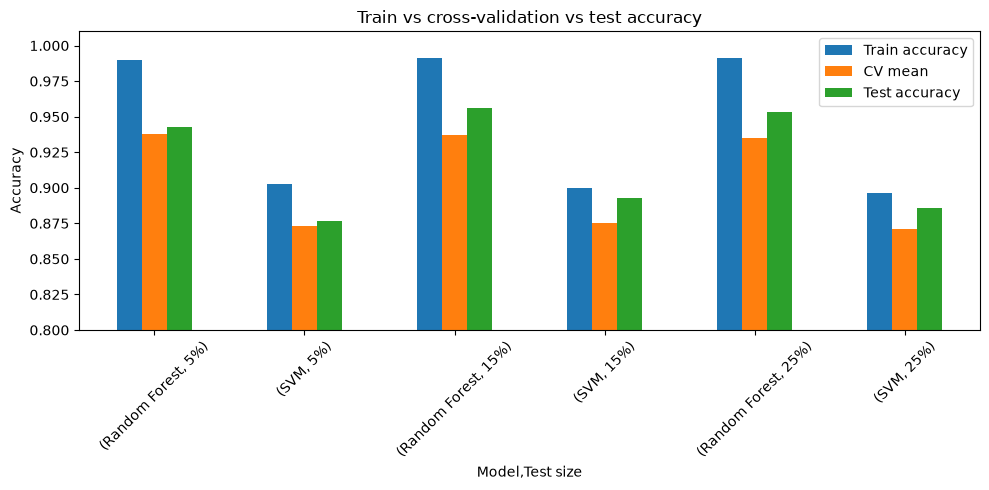

In [41]:
# Train, CV and test accuracy for each model and split
ax = results_df.set_index(['Model', 'Test size'])[['Train accuracy', 'CV mean', 'Test accuracy']].plot(
    kind='bar', figsize=(10, 5))
ax.set_title('Train vs cross-validation vs test accuracy')
ax.set_ylabel('Accuracy')
ax.set_ylim(0.8, 1.01)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

- **Overfitting** happens when a model performs much better on the training data than on new data. The Random Forest (default and tuned) reaches about 99% training accuracy, while its CV and test accuracy are about 94-96%, so it partly memorises the training data. The tuned SVM shows a similar but smaller effect (train-test gap of 0.054, section 8.3).
- **Underfitting** happens when a model is too simple and performs poorly on both training and test data. Neither model underfits here: both reach CV and test accuracy well above the 78% baseline of always predicting Normal.
- **Generalisation.** For every split, the test accuracy is within about 0.02 of the CV mean, and the CV standard deviation is small (at most 0.022). This shows that the results are stable and that the models generalise well to unseen records. The 5% split is the least reliable estimate because its test set is very small.

## 10. Conclusion

The Random Forest is preferred for predicting the fetal state, because it achieved the higher macro-F1 and Pathologic recall on the test set, with stable cross-validation results. The most important features are `ASTV` and `ALTV` (abnormal short-term and long-term variability) and `AC` (accelerations), which were ranked highly by both the ANOVA and the models. `DP` was the strongest feature in the ANOVA but was used much less by the models, probably because its information overlaps with other features.

The work has several limitations. The data comes from a single hospital, so the models may not generalise to other populations or equipment. The Suspect and Pathologic classes are small, which makes their metrics less stable. The 5% split gives an unreliable test estimate because of its very small test set. Future work could use oversampling techniques such as SMOTE (Chawla et al., 2002) to handle the class imbalance, test the models on data from other hospitals, or collect more pathologic cases.

## References

Ayres de Campos, D., Bernardes, J., Garrido, A., Marques de Sá, J. and Pereira Leite, L. (2000) 'SisPorto 2.0: a program for automated analysis of cardiotocograms', *Journal of Maternal-Fetal Medicine*, 9(5), pp. 311-318.

Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5-32.

Campos, D. and Bernardes, J. (2000) *Cardiotocography* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C51S4N (Accessed: 18 November 2026).

Chawla, N.V., Bowyer, K.W., Hall, L.O. and Kegelmeyer, W.P. (2002) 'SMOTE: synthetic minority over-sampling technique', *Journal of Artificial Intelligence Research*, 16, pp. 321-357.

Cortes, C. and Vapnik, V. (1995) 'Support-vector networks', *Machine Learning*, 20(3), pp. 273-297.

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.